# Đồ thị 05 ECDF của creatinine phosphokinase

**Võ Minh Huy — 2311110117**

ECDF tại t = số hồ sơ có CPK ≤ t / tổng số hồ sơ. Dùng đủ 299 hồ sơ sau xử lý, giữ nguyên các giá trị cao. Trục X dùng thang logarithm để đọc rõ cả vùng tập trung và phần đuôi; các giá trị CPK hiển thị vẫn theo U/L. Trục Y là tỷ lệ tích lũy.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, ScalarFormatter

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
cpk = pd.to_numeric(du_lieu["creatinine_phosphokinase"], errors="raise")
if len(cpk) != 299 or cpk.isna().any() or not np.isfinite(cpk).all() or (cpk <= 0).any():
    raise ValueError("Cần đủ 299 giá trị CPK dương, hữu hạn để dùng trục log.")
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/05_ecdf_cpk"
thu_muc_kq.mkdir(parents=True, exist_ok=True)
thong_ke = pd.DataFrame({"SoHoSo":[len(cpk)], "Min":[cpk.min()],
    "Q1":[cpk.quantile(0.25)], "Median":[cpk.median()],
    "Q3":[cpk.quantile(0.75)], "Max":[cpk.max()], "Mean":[cpk.mean()]})
thong_ke.round(2)


,SoHoSo,Min,Q1,Median,Q3,Max,Mean
0,299,23.0,120.0,249.0,582.0,7861.0,552.71


In [2]:
gia_tri, so_luong = np.unique(cpk.to_numpy(), return_counts=True)
so_tich_luy = np.cumsum(so_luong)
ty_le = so_tich_luy / len(cpk)
assert so_luong.sum() == 299 and ty_le[-1] == 1
assert np.all(np.diff(gia_tri) > 0) and np.all(np.diff(ty_le) > 0)
assert np.allclose(ty_le, [(cpk <= t).mean() for t in gia_tri])
bang_ecdf = pd.DataFrame({"CPK":gia_tri, "SoHoSoTaiGiaTri":so_luong,
    "SoHoSoTichLuy":so_tich_luy, "TyLeTichLuy":ty_le})
moc = [120, 249, 582, 1000]
bang_moc = pd.DataFrame({"CPKNhoHonHoacBang":moc,
    "SoHoSo":[int((cpk <= t).sum()) for t in moc],
    "TyLePhanTram":[round(100*(cpk <= t).mean(), 2) for t in moc]})
bang_moc


,CPKNhoHonHoacBang,SoHoSo,TyLePhanTram
0,120,75,25.08
1,249,150,50.17
2,582,242,80.94
3,1000,268,89.63


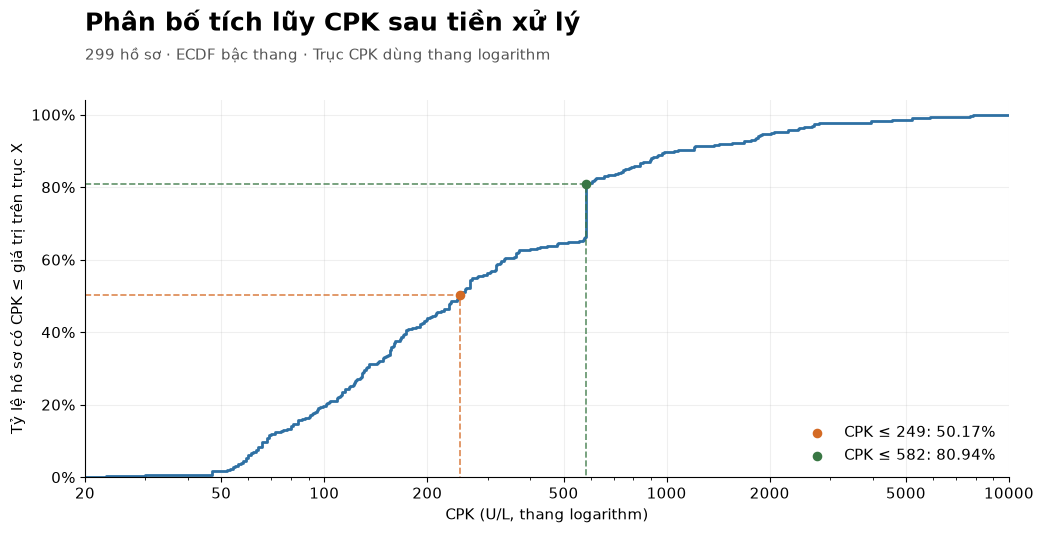

In [3]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11})
fig, ax = plt.subplots(figsize=(10.5, 5.8))
fig.subplots_adjust(top=0.82, bottom=0.17, left=0.10, right=0.98)
fig.text(0.10, 0.94, "Phân bố tích lũy CPK sau tiền xử lý", fontsize=18, weight="bold")
fig.text(0.10, 0.89, "299 hồ sơ · ECDF bậc thang · Trục CPK dùng thang logarithm", color="#555555")
# Bậc thang phải liên tục: tại mỗi giá trị, lấy toàn bộ hồ sơ bằng giá trị đó.
x_ve = np.r_[20, gia_tri, 10000]
y_ve = np.r_[0, ty_le, 1]
ax.step(x_ve, y_ve, where="post", color="#2E70A3", linewidth=2)
ax.set_xscale("log")
for t, mau in [(249,"#D46A24"), (582,"#397744")]:
    f = float((cpk <= t).mean())
    ax.plot([20,t,t], [f,f,0], linestyle="--", color=mau, linewidth=1.2, alpha=0.8)
    ax.scatter([t],[f],color=mau,s=35,zorder=3,
        label=f"CPK ≤ {t}: {100*f:.2f}%")
ax.set(xlabel="CPK (U/L, thang logarithm)", ylabel="Tỷ lệ hồ sơ có CPK ≤ giá trị trên trục X",
    xlim=(20,10000), ylim=(0,1.04))
ax.set_xticks([20,50,100,200,500,1000,2000,5000,10000])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
fig.savefig(thu_muc_kq / "05_ecdf_cpk.png", dpi=300, bbox_inches="tight", facecolor="white")
thong_ke.to_csv(thu_muc_kq / "thong_ke_python.csv", index=False, encoding="utf-8-sig")
bang_moc.to_csv(thu_muc_kq / "moc_tich_luy_python.csv", index=False, encoding="utf-8-sig")
bang_ecdf.to_csv(thu_muc_kq / "ecdf_python.csv", index=False, encoding="utf-8-sig")
plt.show()


## Nhận xét

ECDF không giảm và đạt 100% tại CPK lớn nhất 7.861 U/L. Median là 249 U/L; bảng mốc cho tỷ lệ thực tế có CPK ≤ 249 và ≤ 582. Do có giá trị trùng, tỷ lệ tích lũy tại median có thể vượt 50%; không ép đường ECDF đi qua đúng 50% tại median.

Trục log chỉ thay cách hiển thị khoảng cách trên trục X, không thay CPK trong dữ liệu hoặc phép đếm. Các mốc minh họa không phải ngưỡng chẩn đoán. Dữ liệu sau xử lý có cả 21 giá trị CPK được điền hoặc thay ở N03; không suy ra đây là phân bố nguyên gốc chưa chỉnh sửa.
